# <span style='color:deepskyblue'>Chapter 2</span>

In [18]:
import numpy as np
import random 
import matplotlib.pyplot as plt    

In [19]:
#Random number configuration
rng = np.random.default_rng()

------------------------------------

##### b) Write a MATLAB script that can generate trajectories for bacteria motion based on the probability distribution:

$$
P(\phi) = \frac{1}{2\pi}\left(1 + A\cos\phi\right)
$$

Probability Denisty:

In [20]:
def probability_density(phi, A):
    """
    P(phi) from Eq. 2.3. 
    A in [0, 1] controls the bias strength.
    """
    return (1.0 / (2.0 * np.pi)) * (1.0 + A * np.cos(phi))

Rejection Sampling:

In [21]:
def sample_phi(A, rng=rng):
    """
    Draw a single angle phi from P(phi; A) using rejection sampling.
 
    P(phi) is maximal at phi = 0, where P(0) = (1 + A) / (2*pi) -> Rejectionheight.
    """
    p_max = (1.0 + A) / (2.0 * np.pi)
 
    while True:
        phi_trial = rng.uniform(0.0, 2.0 * np.pi)
        y_trial = rng.uniform(0.0, p_max)
        if y_trial <= probability_density(phi_trial, A):
            return phi_trial

Trajectory Generation:

In [22]:
def step_xy(r, phi, x0, y0):
    """
    Cartesian displacement of one step (Eq. 2.2).
    """
    x = x0 + r * np.cos(phi)
    y = y0 + r * np.sin(phi)
    return x, y


def generate_trajectory(num_steps, r, A):
    """
    Build one N-step trajectory. Returns an (num_steps+1, 2) array
    of (x, y) positions, starting at the origin.
    """
    positions = np.zeros((num_steps + 1, 2))
    
    for i in range(1, num_steps + 1):
        phi = sample_phi(A)
        x_prev, y_prev = positions[i - 1]
        positions[i] = step_xy(r, phi, x_prev, y_prev)
    return positions

In [ ]:
def verify_sampling(A, n_samples=200_000, n_bins=60):

    samples = np.array([sample_phi(A) for _ in range(n_samples)])
 
    phi_grid = np.linspace(0, 2 * np.pi, 400) # X axis 
    theory = probability_density(phi_grid, A)
 
    plt.figure(figsize=(7, 4))
    plt.hist(samples, bins=n_bins, density=True, alpha=0.6,
              label="sampled histogram")
    plt.plot(phi_grid, theory, "r-", lw=2, label="P(phi) theory")
    plt.title(f"Rejection sampling check (A = {A})")
    plt.xlabel("phi (rad)")
    plt.ylabel("probability density")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
 

In [ ]:
def plot_trajectories(num_steps, num_bacteria, r, A):
    plt.figure(figsize=(7, 7))
    
    for i in range(num_bacteria):
        traj = generate_trajectory(num_steps, r, A)
        x, y = traj[:, 0], traj[:, 1]
 
        plt.plot(x, y, linewidth=0.6, label=f"Bacteria {i+1}")
        plt.scatter(x[0], y[0], color="green", zorder=5)   # start
        plt.scatter(x[-1], y[-1], color="red", zorder=5)   # end
 
    plt.title(f"Bacteria trajectories (A = {A}, N = {num_steps} steps)")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.axis("equal")
    plt.grid(alpha=0.3)
    if num_bacteria <= 10:
        plt.legend(fontsize=7)
    plt.tight_layout()
    plt.show()

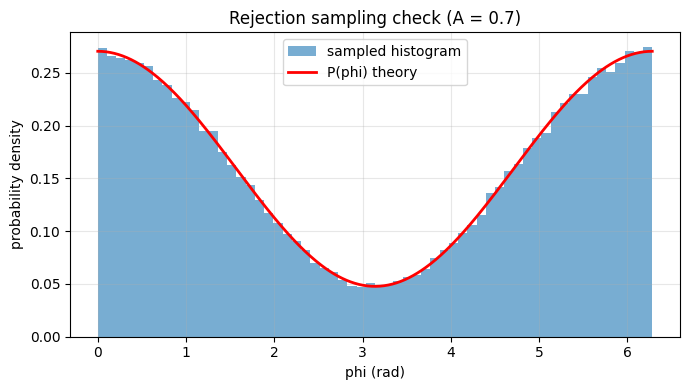

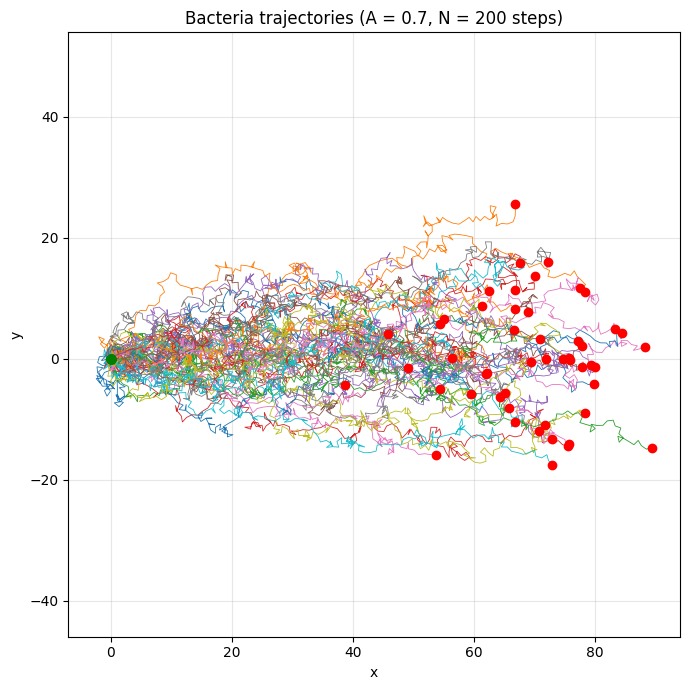

In [28]:
A = 0.7   # bias strength, 0 <= A <= 1
r = 1.0   # fixed step length
 
verify_sampling(A)
plot_trajectories(num_steps=200, num_bacteria=50, r=r, A=A)